In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import commun

x, dx = commun.grille(11)
print(commun.laplacien_1d(x))

[[   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]
 [ 100. -200.  100.    0.    0.    0.    0.    0.    0.    0.    0.]
 [   0.  100. -200.  100.    0.    0.    0.    0.    0.    0.    0.]
 [   0.    0.  100. -200.  100.    0.    0.    0.    0.    0.    0.]
 [   0.    0.    0.  100. -200.  100.    0.    0.    0.    0.    0.]
 [   0.    0.    0.    0.  100. -200.  100.    0.    0.    0.    0.]
 [   0.    0.    0.    0.    0.  100. -200.  100.    0.    0.    0.]
 [   0.    0.    0.    0.    0.    0.  100. -200.  100.    0.    0.]
 [   0.    0.    0.    0.    0.    0.    0.  100. -200.  100.    0.]
 [   0.    0.    0.    0.    0.    0.    0.    0.  100. -200.  100.]
 [   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.]]


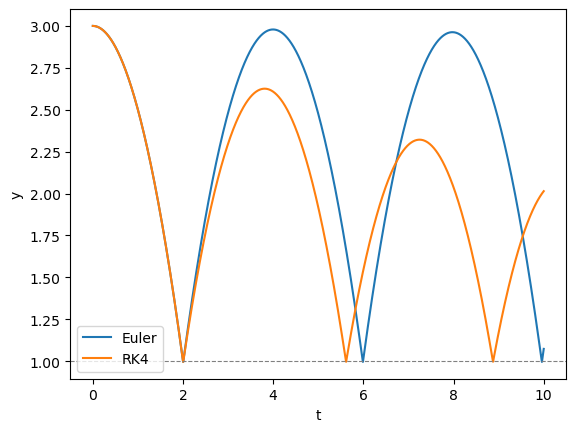

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#modéliser la bille et sa dynamique

#test 1 : une bille rebondit sur le sol : 

#param du pb
m = 1      
r = 1          
g = 1.0        
k_n = 2e5        # raideur normale du contact
e = 0.9 


#grandeurs du probleme
omega   = np.sqrt(k_n / m)                                # pulsation du contact
zeta    = -np.log(e) / np.sqrt(np.pi**2 + np.log(e)**2)   # taux d'amortissement
gamma_n = 2 * zeta * omega                                # coefficient d'amortissement
t_c     = np.pi / (omega * np.sqrt(1 - zeta**2))          # durée d'un choc

# CI
y_0 = 3
v_0 = 0

T  = 10.0
dt = t_c / 50

def a(y, v):
    delta = r-y
    if delta < 0:
        return -g
    else:
        return -g + max(0, k_n*delta - gamma_n*m*v)/m
    
 
def Euler(y, v, dt):
    y_new = y + dt*v
    v_new = v + dt*a(y, v)
    return y_new, v_new


def RK4(y, v, dt):
    k1_y = v
    k1_v = a(y, v)
    k2_y = v + dt/2 * k1_v
    k2_v = a(y + dt/2 * k1_y, v + dt/2 * k1_v)
    k3_y = v + dt/2 * k2_v
    k3_v = a(y + dt/2 * k2_y, v + dt/2 * k2_v)
    k4_y = v + dt * k3_v
    k4_v = a(y + dt * k3_y, v + dt * k3_v)

    y_new = y + dt/6 * (k1_y + 2*k2_y + 2*k3_y + k4_y)
    v_new = v + dt/6 * (k1_v + 2*k2_v + 2*k3_v + k4_v)
    return y_new, v_new

#simulation de l'expérience
def simulation(schema, T, dt):
    n = int(T/dt) +1
    t = np.arange(n)*dt
    y = np.zeros(n)
    v = np.zeros(n)
    y[0] = y_0
    v[0] = v_0
    for i in range(n-1):
        y[i+1], v[i+1] = schema(y[i], v[i], dt)
    return t, y, v


for nom, schema in [("Euler", Euler),  ("RK4", RK4)]:
    t, y, v = simulation (schema, T, dt)
    plt.plot(t, y, label=nom)
plt.axhline(r, color="gray", ls="--", lw=0.8)   
plt.xlabel("t"); plt.ylabel("y"); plt.legend()
plt.show()

On voit ici que le schéma d'Euler explicite n'est pas acceptable car l'amortissement physique est compensé par l'ajout généré par le schéma d'euler, faisant que la bille rebondit quasiment toujours à la même hauteur, comme si elle était parfaitement élastique

In [ ]:
#passons au modèle 2D et avec les intéractions avec les autres billes


